In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

df = pd.read_csv("telecom_churn.csv")
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 20030 entries, 0 to 20029
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        20030 non-null  int64  
 1   gender             20030 non-null  str    
 2   senior_citizen     20030 non-null  str    
 3   partner            20030 non-null  str    
 4   dependents         20030 non-null  str    
 5   tenure             19958 non-null  float64
 6   phone_service      20030 non-null  str    
 7   multiple_lines     20030 non-null  str    
 8   internet_service   20030 non-null  str    
 9   online_security    20030 non-null  str    
 10  online_backup      20030 non-null  str    
 11  device_protection  20030 non-null  str    
 12  tech_support       20030 non-null  str    
 13  streaming_tv       20030 non-null  str    
 14  streaming_movies   20030 non-null  str    
 15  contract           20030 non-null  str    
 16  paperless_billing  20030 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,20030.0,NaN,NaN,NaN,11001.761108,5773.850569,1001.0,6002.25,11001.5,16002.75,21000.0
gender,20030,6,Female,8031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
senior_citizen,20030,4,0,14105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
partner,20030,4,No,9033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,20030,4,No,12162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,19958.0,NaN,NaN,NaN,36.019341,22.499997,0.0,17.0,36.0,54.0,198.0
phone_service,20030,4,Yes,15948,NaN,NaN,NaN,NaN,NaN,NaN,NaN
multiple_lines,20030,5,Yes,8072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_service,20030,5,Fiber optic,6922,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_security,20030,5,No,8143,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df = df.drop(columns=["customer_id", "internal_flag"])

In [3]:
def to_num(s):
    if pd.isna(s): return np.nan
    return pd.to_numeric(
        str(s).replace("$", "").replace(",", "").replace(" ", "").strip(),
        errors="coerce"
    )

df["monthly_charges"] = df["monthly_charges"].map(to_num)
df["total_charges"]   = df["total_charges"].map(to_num)
df["tenure"]          = pd.to_numeric(df["tenure"], errors="coerce")

In [4]:
def norm(x):
    return str(x).strip().lower() if pd.notna(x) else x

cat_cols = ["gender","partner","dependents","phone_service","multiple_lines",
            "internet_service","online_security","online_backup",
            "device_protection","tech_support","streaming_tv","streaming_movies",
            "contract","paperless_billing","payment_method","churn"]

for c in cat_cols:
    df[c] = df[c].map(norm)

df["gender"] = df["gender"].replace({"f":"female","m":"male"})
for c in ["partner","dependents","phone_service","paperless_billing","churn"]:
    df[c] = df[c].replace({"y":"yes","n":"no"})

df["internet_service"] = df["internet_service"].replace({"fiber":"fiber optic"})
df["contract"] = df["contract"].replace({"month to month":"month-to-month"})
df["payment_method"] = df["payment_method"].replace({
    "e-check":"electronic check","electronic check":"electronic check"
})

In [5]:
df["senior_citizen"] = df["senior_citizen"].map(
    lambda x: 1 if str(x).strip().lower() in ("yes","1","true") 
              else (0 if str(x).strip().lower() in ("no","0","false") else np.nan)
)

tenure {'mean': np.float64(36.019340615292116), 'median': np.float64(36.0), 'std': np.float64(22.49999697630162), 'min': np.float64(0.0), 'q1': np.float64(17.0), 'q3': np.float64(54.0), 'max': np.float64(198.0), 'skew': np.float64(0.8148423901753257), 'kurt': np.float64(3.6727341752867217)}
monthly_charges {'mean': np.float64(75.11256625162184), 'median': np.float64(70.18), 'std': np.float64(60.55539583939771), 'min': np.float64(20.02), 'q1': np.float64(45.04), 'q3': np.float64(95.15), 'max': np.float64(798.6516211), 'skew': np.float64(7.051771912854667), 'kurt': np.float64(66.00201429746026)}
total_charges {'mean': np.float64(4048.2282414468264), 'median': np.float64(4045.915), 'std': np.float64(2287.537706407896), 'min': np.float64(100.47), 'q1': np.float64(2071.3), 'q3': np.float64(6035.38), 'max': np.float64(7999.03), 'skew': np.float64(-0.0006382560481374308), 'kurt': np.float64(-1.208980123711557)}


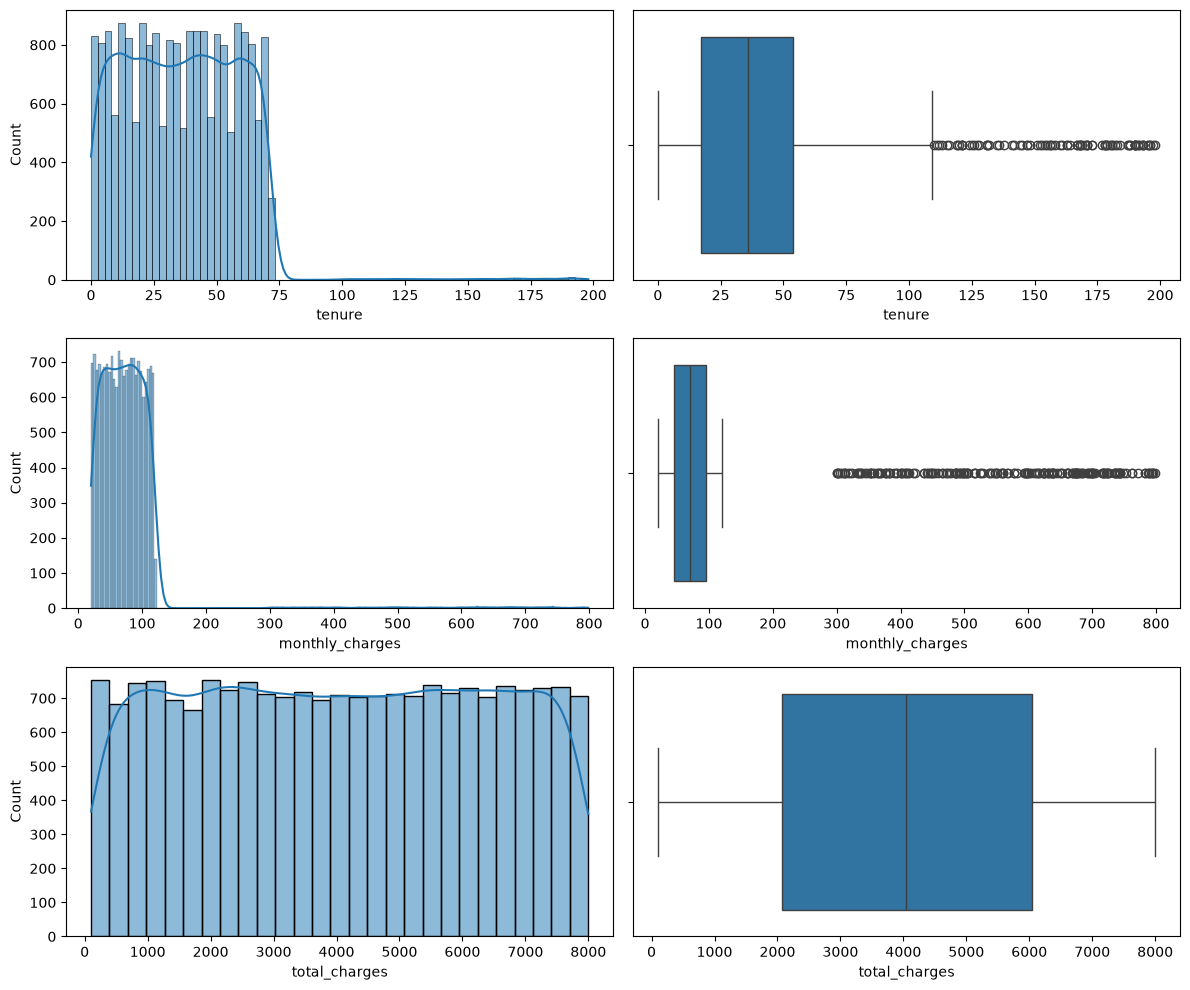

In [6]:
num_cols = ["tenure","monthly_charges","total_charges"]

for c in num_cols:
    s = df[c]
    print(c, {
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "min": s.min(), "q1": s.quantile(.25), "q3": s.quantile(.75),
        "max": s.max(), "skew": s.skew(), "kurt": s.kurt()
    })

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for i, c in enumerate(num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=axes[i,0])
    sns.boxplot(x=df[c].dropna(), ax=axes[i,1])
plt.tight_layout()

In [7]:
# IQR
for c in num_cols:
    q1, q3 = df[c].quantile([.25,.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    print(c, "IQR outliers:", ((df[c]<lo)|(df[c]>hi)).sum())

# Z-score
for c in num_cols:
    z = np.abs(stats.zscore(df[c].dropna()))
    print(c, "Z>3:", (z>3).sum())

tenure IQR outliers: 91
monthly_charges IQR outliers: 200
total_charges IQR outliers: 0
tenure Z>3: 96
monthly_charges Z>3: 200
total_charges Z>3: 0


# проверка гит